# 05 Star Cluster Maps


In [ ]:
from pathlib import Path

def find_project_root(start=None):
    """Locate the project root from the working directory or an ancestor."""
    location = Path(start or Path.cwd()).resolve()
    for candidate in (location, *location.parents):
        if (candidate / "README.md").exists() and (candidate / "notebooks").is_dir():
            return candidate
    raise FileNotFoundError("Run Jupyter from the repository root or notebooks/ directory. The README.md and notebooks/ folder must exist.")

PROJECT_ROOT = find_project_root()
DATA_DIR = PROJECT_ROOT / "data"
RESULTS_DIR = PROJECT_ROOT / "results"
SPECTRA_DIR = PROJECT_ROOT / "spectra"
FIGURES_DIR = PROJECT_ROOT / "figures"
SAVE_FIGURES = False  # Figures render inline; optional exports disabled by default.
SAVE_TABLES = True    # Intermediate tables are required by downstream notebooks.
# Output folders are part of the repository layout; raw data remains private.


> **Archived results:** Both SSC maps and the near-infrared reference image were restored from the original notebook. The saved surface-density table is displayed below. Input maps are not distributed; a full rerun requires authorized observational files.


In [ ]:
from pathlib import Path
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.patches import Circle
import matplotlib.patheffects as pe

from astropy.io import fits
from astropy.wcs import WCS, FITSFixedWarning
from astropy.wcs.utils import proj_plane_pixel_scales
from astropy.coordinates import SkyCoord
import astropy.units as u
from astropy.visualization import ImageNormalize, AsinhStretch

warnings.simplefilter("ignore", FITSFixedWarning)

BASE_DIR = PROJECT_ROOT
FIG_DIR = FIGURES_DIR / "maps"
RES_SSC  = BASE_DIR / "results" / "ResultadosSCCs"
RES_CO   = BASE_DIR / "results" / "ResultadosCO"

FIG_DIR.mkdir(parents=True, exist_ok=True)

FILE_SSC_DENSITY = RES_SSC / "SSCs_SurfaceDensity.fits"
FILE_NIR_KS      = RES_SSC / "NGC3110-NIR-Zara-wreg.fits"

# Cambia este nombre por tu FITS real de CO(1-0), momento 0.
FILE_CO10_MOM0   = RES_CO / "line_12co10_contsub_clean20_nat.regrid.immath.moment0.fits"

# Si tienes una máscara oficial de CO(1-0), pon aquí la ruta.
# Si no, déjalo en None.
FILE_CO10_MASK   = None

# Si no tienes máscara oficial:
# "positive" -> si el mapa de momento 0 ya está enmascarado.
# "snr"      -> si tienes rms del mapa de momento 0.
# "fraction" -> si quieres usar una fracción del pico de CO, no del mapa de SSCs.
CO_MASK_KIND  = "positive"
CO10_MOM0_RMS = None
CO_MASK_SIGMA = 3.0
CO_MASK_FRAC  = 0.05

KPC_PER_ARCSEC = 0.325
NU_DENSE_GAS_GHZ = 88.400
FWHM_DENSE_GAS = 2460.0 / NU_DENSE_GAS_GHZ

POINTINGS = {
    "CEN": SkyCoord("10:04:02.110", "-06:28:29.200", unit=(u.hourangle, u.deg), frame="icrs"),
    "NOR": SkyCoord("10:04:01.210", "-06:28:12.200", unit=(u.hourangle, u.deg), frame="icrs"),
    "SOU": SkyCoord("10:04:02.500", "-06:28:48.000", unit=(u.hourangle, u.deg), frame="icrs"),
}

SSC_COUNTS = {
    "NOR": 66,
    "CEN": 274,
    "SOU": 47,
}

In [ ]:
def load_2d_fits(filename):
    filename = Path(filename)
    if not filename.exists():
        raise FileNotFoundError(f"No existe el archivo: {filename}")

    with fits.open(filename) as hdul:
        data = np.squeeze(hdul[0].data).astype(float)
        header = hdul[0].header.copy()

    if data.ndim != 2:
        raise ValueError(f"{filename.name} no queda 2D tras squeeze; ndim = {data.ndim}")

    wcs = WCS(header).celestial
    return data, header, wcs


def pixel_area_kpc2(wcs, kpc_per_arcsec=KPC_PER_ARCSEC):
    scales_deg = proj_plane_pixel_scales(wcs)
    pix_area_arcsec2 = abs(scales_deg[0] * scales_deg[1]) * 3600.0**2
    return pix_area_arcsec2 * kpc_per_arcsec**2


def sky_separation_grid(wcs, shape, coord):
    ny, nx = shape
    ypix, xpix = np.indices((ny, nx))
    sky = wcs.pixel_to_world(xpix, ypix)
    return sky.separation(coord).arcsec


def clean_pointing_name(name):
    return {"NOR": "North", "CEN": "Center", "SOU": "South"}.get(name.upper(), name)


def make_co_mask(co_data, mask_data=None, kind="positive", rms=None, sigma=3.0, frac=0.05):
    if mask_data is not None:
        if mask_data.shape != co_data.shape:
            raise ValueError("La máscara de CO y el mapa CO(1-0) no tienen la misma forma.")
        return np.isfinite(mask_data) & (mask_data > 0)

    finite = np.isfinite(co_data)

    if kind == "positive":
        return finite & (co_data > 0)

    if kind == "snr":
        if rms is None:
            raise ValueError("Para CO_MASK_KIND='snr' debes fijar CO10_MOM0_RMS.")
        return finite & (co_data > sigma * rms)

    if kind == "fraction":
        return finite & (co_data > frac * np.nanmax(co_data))

    raise ValueError("CO_MASK_KIND debe ser 'positive', 'snr' o 'fraction'.")


ssc_map, h_ssc, w_ssc = load_2d_fits(FILE_SSC_DENSITY)
nir_map, h_nir, w_nir = load_2d_fits(FILE_NIR_KS)
co10_map, h_co10, w_co10 = load_2d_fits(FILE_CO10_MOM0)

if FILE_CO10_MASK is not None:
    co10_mask_map, h_co10_mask, w_co10_mask = load_2d_fits(FILE_CO10_MASK)
    co10_mask = make_co_mask(co10_map, mask_data=co10_mask_map)
else:
    co10_mask = make_co_mask(
        co10_map,
        kind=CO_MASK_KIND,
        rms=CO10_MOM0_RMS,
        sigma=CO_MASK_SIGMA,
        frac=CO_MASK_FRAC,
    )

print(f'FWHM dense-gas beam = {FWHM_DENSE_GAS:.2f}"')
print(f"CO-mask pixels = {np.sum(co10_mask)}")

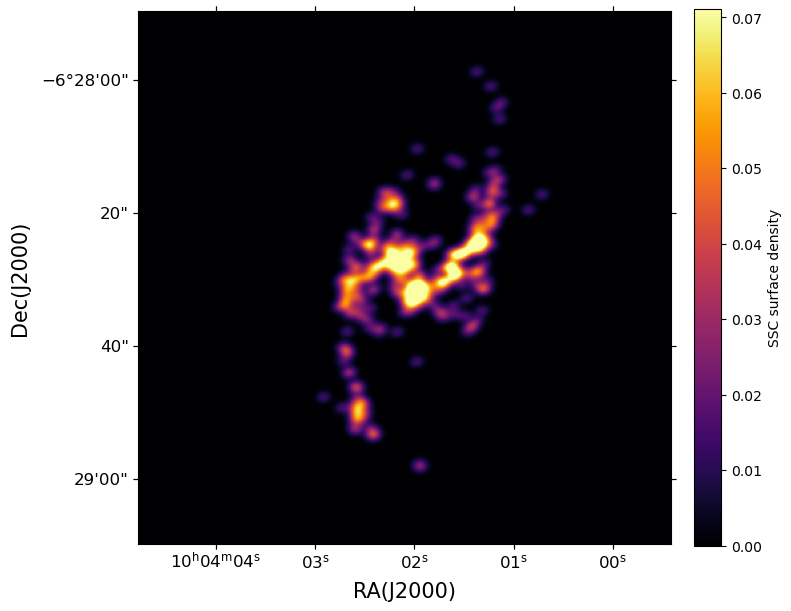

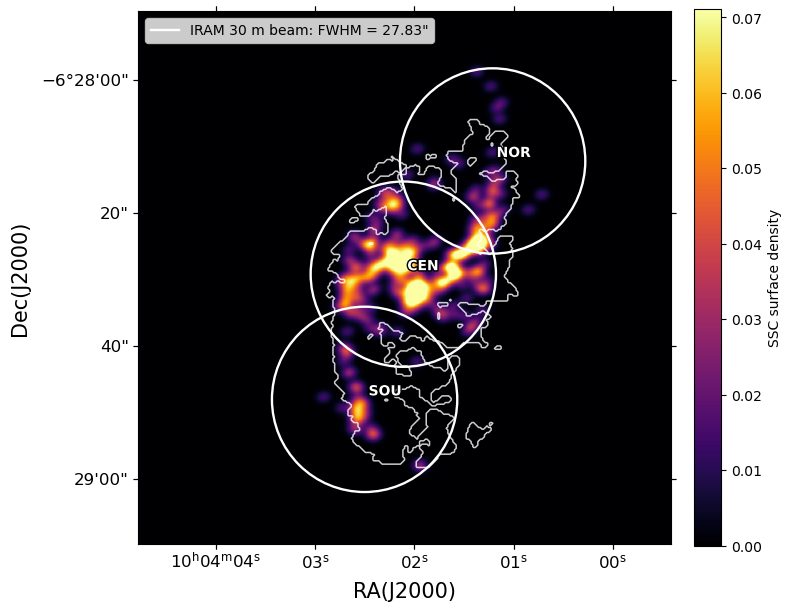

In [6]:
def plot_ssc_map(data, wcs, output_name, with_pointings=True, co_mask=None, co_wcs=None):
    fig = plt.figure(figsize=(8, 7))
    ax = plt.subplot(projection=wcs)

    finite = np.isfinite(data)
    vmin = 0.0
    vmax = np.nanpercentile(data[finite], 99.5)

    im = ax.imshow(data, origin="lower", cmap="inferno", vmin=vmin, vmax=vmax)

    cbar = plt.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
    cbar.set_label(r"SSC surface density")

    if co_mask is not None and co_wcs is not None:
        ax.contour(
            co_mask.astype(float),
            levels=[0.5],
            colors="white",
            linewidths=1.1,
            alpha=0.8,
            transform=ax.get_transform(co_wcs),
        )

    if with_pointings:
        pix_scale = abs(proj_plane_pixel_scales(wcs)[0]) * 3600.0
        radius_pix = (FWHM_DENSE_GAS / 2.0) / pix_scale

        for name, coord in POINTINGS.items():
            xpix, ypix = wcs.world_to_pixel(coord)
            ax.add_patch(
                Circle(
                    (xpix, ypix),
                    radius_pix,
                    edgecolor="white",
                    facecolor="none",
                    lw=1.7,
                )
            )
            ax.text(
                xpix + 3,
                ypix + 3,
                name,
                color="white",
                fontsize=10,
                weight="bold",
                path_effects=[pe.withStroke(linewidth=2, foreground="black")],
            )

        label = f'IRAM 30 m beam: FWHM = {FWHM_DENSE_GAS:.2f}"'
        ax.legend(
            [Line2D([0], [0], color="white", lw=1.7)],
            [label],
            loc="upper left",
        )

    ax.set_xlabel("RA(J2000)", fontsize=15)
    ax.set_ylabel("Dec(J2000)", fontsize=15)
    ax.tick_params("both", labelsize=12)

    plt.tight_layout()
    if SAVE_FIGURES: plt.savefig(FIG_DIR / output_name, dpi=400, bbox_inches="tight")
    plt.show()


plot_ssc_map(
    ssc_map,
    w_ssc,
    output_name="SSC_density_map_no_pointings.png",
    with_pointings=False,
)

plot_ssc_map(
    ssc_map,
    w_ssc,
    output_name="SSC_density_map_with_pointings_COmask.png",
    with_pointings=True,
    co_mask=co10_mask,
    co_wcs=w_co10,
)

In [7]:
def compute_sigma_ssc_using_co_mask(co_mask, co_wcs, pointings, ssc_counts, fwhm_arcsec):
    rows = []
    radius_arcsec = fwhm_arcsec / 2.0
    pix_area = pixel_area_kpc2(co_wcs)

    for key, coord in pointings.items():
        sep_arcsec = sky_separation_grid(co_wcs, co_mask.shape, coord)

        aperture_mask = sep_arcsec <= radius_arcsec
        molecular_mask = aperture_mask & co_mask

        n_pix_co = int(np.sum(molecular_mask))
        area_co_kpc2 = n_pix_co * pix_area

        n_pix_ap = int(np.sum(aperture_mask))
        area_ap_kpc2 = n_pix_ap * pix_area

        n_ssc = int(ssc_counts[key])
        sigma_ssc = n_ssc / area_co_kpc2 if area_co_kpc2 > 0 else np.nan
        f_co = area_co_kpc2 / area_ap_kpc2 if area_ap_kpc2 > 0 else np.nan

        rows.append({
            "Pointing": clean_pointing_name(key),
            "N_SSC": n_ssc,
            "N_pix_CO": n_pix_co,
            "A_CO_kpc2": area_co_kpc2,
            "A_aperture_kpc2": area_ap_kpc2,
            "f_CO": f_co,
            "Sigma_SSC_kpc2": sigma_ssc,
        })

    table = pd.DataFrame(rows)
    order = ["North", "Center", "South"]
    table["Pointing"] = pd.Categorical(table["Pointing"], categories=order, ordered=True)
    return table.sort_values("Pointing").reset_index(drop=True)


ssc_density_co_table = compute_sigma_ssc_using_co_mask(
    co_mask=co10_mask,
    co_wcs=w_co10,
    pointings=POINTINGS,
    ssc_counts=SSC_COUNTS,
    fwhm_arcsec=FWHM_DENSE_GAS,
)

from IPython.display import display
display(ssc_density_co_table)

if SAVE_TABLES:
    (RESULTS_DIR / "ResultadosSCCs").mkdir(parents=True, exist_ok=True)
    ssc_density_co_table.to_csv(
        RESULTS_DIR / "ResultadosSCCs" / "SSC_density_using_CO10_mask.csv",
        index=False,
    )

Pointing  N_SSC  N_pix_CO  A_CO_kpc2  A_aperture_kpc2      f_CO  \
0    North     66      3087  20.379023        64.259609  0.317136   
1   Center    274      7733  51.049883        64.253008  0.794514   
2    South     47      4362  28.796016        64.239805  0.448258   

   Sigma_SSC_kpc2  
0        3.238624  
1        5.367299  
2        1.632170

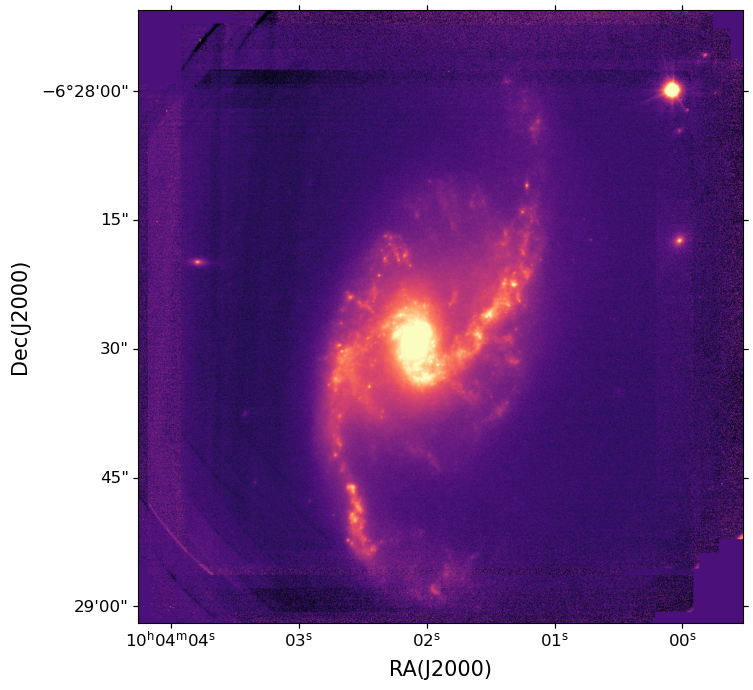

In [9]:
def plot_nir_ks(data, wcs, output_name="NIR_Ks_image.png"):
    finite = np.isfinite(data)
    vmin = np.nanpercentile(data[finite], 1)
    vmax = np.nanpercentile(data[finite], 99.7)

    norm = ImageNormalize(vmin=vmin, vmax=vmax, stretch=AsinhStretch())

    fig = plt.figure(figsize=(8, 7))
    ax = plt.subplot(projection=wcs)

    ax.imshow(data, origin="lower", cmap="magma", norm=norm)

    ax.set_xlabel("RA(J2000)", fontsize=15)
    ax.set_ylabel("Dec(J2000)", fontsize=15)
    ax.tick_params("both", labelsize=12)

    plt.tight_layout()
    if SAVE_FIGURES: plt.savefig(FIG_DIR / output_name, dpi=400, bbox_inches="tight")
    plt.show()


plot_nir_ks(nir_map, w_nir)